## CS435/535 Performance - Fall 2026

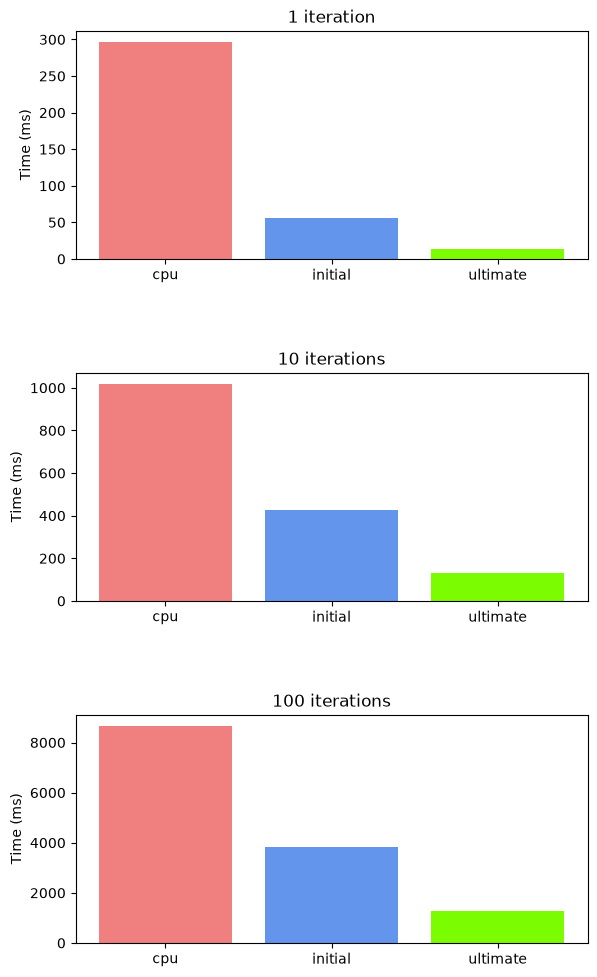

In [68]:
import matplotlib.pyplot as plt
import json

js = '[{"alg": 0, "iters": 1, "time": 296.795706}, {"alg": 0, "iters": 10, "time": 1018.871283}, {"alg": 0, "iters": 100, "time": 8668.452440}, {"alg": 1, "iters": 1, "time": 56.558208}, {"alg": 1, "iters": 10, "time": 425.135773}, {"alg": 1, "iters": 100, "time": 3826.624512}, {"alg": 15, "iters": 1, "time": 13.309728}, {"alg": 15, "iters": 10, "time": 129.594940}, {"alg": 15, "iters": 100, "time": 1282.196655}]'

d = json.loads(js)

# order by iterations -> algorithm -> time
data = {}
for item in d:
    if item['iters'] in data:
        data[item['iters']][str(item['alg'])] = item['time']
    else:
        data[item['iters']] = {str(item['alg']): item['time']}

# print(data)

fig, axs = plt.subplots(len(data))
fig.subplots_adjust(left=0.1, bottom=0.1, right=0.9, top=2, hspace=0.5, wspace=0.2)
for count, (k, v) in enumerate(data.items()):
    axs[count].set_title(f'{k} iteration{'s' if k > 1 else ''}')
    axs[count].bar(v.keys(), v.values(), color=['lightcoral', 'cornflowerblue', 'lawngreen'])
    axs[count].set_xticks([str(x) for x in v.keys()])
    axs[count].set_xticklabels(['cpu', 'initial', 'ultimate'])
    axs[count].set_ylabel('Time (ms)')



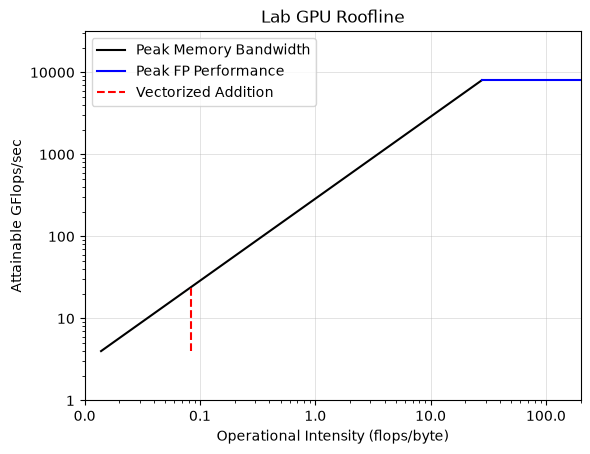

In [1]:
# | echo: false
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# graph limits
min_oi = 1./100
max_oi = 200
min_tflops = 1
max_tflops = 32000

bandwidth_line_scaling = 2000

nvidia_max = 8000 # 8 TFlop/s from documentation
mem_bw = 288 # 288 GB/s from documentation

ridge_point_x = nvidia_max/mem_bw
ridge_point_y = nvidia_max

fig, ax = plt.subplots()

plt.title("Lab GPU Roofline")
plt.xlabel('Operational Intensity (flops/byte)')
plt.ylabel('Attainable GFlops/sec')

# memory bandwidth constraint
plt.plot([ridge_point_x/bandwidth_line_scaling, ridge_point_x],
         [ridge_point_y/bandwidth_line_scaling, ridge_point_y], color='black')

# flops constraint
plt.plot([ridge_point_x, max_oi], [nvidia_max, nvidia_max], color='blue')

# vectorized addition utilization
plt.plot([1./12, 1./12], [ridge_point_y/bandwidth_line_scaling, 1./12 * mem_bw], '--r')

plt.grid(True)
plt.loglog()

# set these AFTER loglog
plt.axis((min_oi, max_oi, min_tflops, max_tflops))
ax.yaxis.set_major_formatter(ticker.ScalarFormatter())
ax.xaxis.set_major_formatter(ticker.ScalarFormatter())

plt.legend(['Peak Memory Bandwidth', 'Peak FP Performance', 'Vectorized Addition'],
           loc='upper left')

plt.show()
